In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [4]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['w'])
        nss = sum(df[df.bs==+1]['w'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n_array = []
    wtot_array = []
    for i in range(0, len(w_array)):
        n_array.append( df[df.w == w_array[i]].shape[0] )
        wtot_array.append( sum(df[df.w == w_array[i]]['w']) )
    n = 0
    for i in range(0, len(w_array)):
        if (wtot_array[i] != 0):
            n += wtot_array[i]*n_array[i]/sum(wtot_array)
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err

In [5]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [6]:
observables1 = ['pt','b','dr','z','epair','w','reject','pt1','pt2','qlead','qsublead','y1','y2','phi1','phi2']
observabless1 = ['pts','bs','drs','zs','epairs','ws','rejects','pt1s','pt2s','qleads','qsubleads','y1s','y2s','phi1s','phi2s']

In [7]:
df_allreco = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0615_chargedrc.root', "MatchedTree"),\
                      'pts>15 and bs!=-9 and reject<=0 and rejects<=0')

In [8]:
df_allreco = applyCut(df_allreco, 'not (pts>25 and w>4e-9)') # removes one high weight jet

In [9]:
df_fake1 = applyCut(df_allreco, 'pt==-9')

In [10]:
df_fake2 = applyCut(df_allreco, 'pt!=-9 and b==-9')

In [14]:
df_fake3 = applyCut(df_allreco, 'pt!=-9 and b!=-9 and (distance1>0.02 or distance2>0.02)')

In [15]:
df_allfake = applyCut(df_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')

In [16]:
df_notfakejet = applyCut(df_allreco, 'pt!=-9')

In [11]:
df = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0615_chargedrc.root', "MatchedTree"),\
              'pts>15 and bs!=-9 and b!=-9 and reject<=0 and rejects<=0')

In [12]:
distance1 = []
distance2 = []
for i in range(0,df.shape[0]):
    phi1small = min(df.iloc[i]['phi1'], df.iloc[i]['phi1s'])
    phi1large = max(df.iloc[i]['phi1'], df.iloc[i]['phi1s'])
    phi2small = min(df.iloc[i]['phi2'], df.iloc[i]['phi2s'])
    phi2large = max(df.iloc[i]['phi2'], df.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df.iloc[i]['phi1'], df.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df.iloc[i]['y1']-df.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df.iloc[i]['y2']-df.iloc[i]['y2s'])**2))
df['distance1'] = distance1
df['distance2'] = distance2

In [13]:
distance1 = []
distance2 = []
for i in range(0,df_allreco.shape[0]):
    phi1small = min(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi1large = max(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi2small = min(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    phi2large = max(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_allreco.iloc[i]['y1']-df_allreco.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_allreco.iloc[i]['y2']-df_allreco.iloc[i]['y2s'])**2))
df_allreco['distance1'] = distance1
df_allreco['distance2'] = distance2

Matches

In [17]:
df_match = applyCut(df, 'distance1 < 0.02 and distance2 < 0.02')

In [18]:
df_match.shape[0]

46086

1.1 Fake decomposition

In [19]:
w_array = np.unique(df_allreco['w'])

In [20]:
df_allreco_pts_array = [ df_allreco[(df_allreco.pts>15) & (df_allreco.pts<20)],\
                       df_allreco[(df_allreco.pts>20) & (df_allreco.pts<25)],\
                       df_allreco[(df_allreco.pts>25) & (df_allreco.pts<30)],\
                       df_allreco[(df_allreco.pts>30) & (df_allreco.pts<40)] ]

In [21]:
rc_allreco_bs_vs_pts_array = []
rc_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df_allreco_pts_array)):
    rc_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[0])
    rc_err_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[1])

In [22]:
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)] ]

In [23]:
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[1])

In [24]:
df_allfake_pts_array = [ df_allfake[(df_allfake.pts>15) & (df_allfake.pts<20)],\
                       df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25)],\
                       df_allfake[(df_allfake.pts>25) & (df_allfake.pts<30)],\
                       df_allfake[(df_allfake.pts>30) & (df_allfake.pts<40)] ]

In [25]:
rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[1])

In [26]:
df_fake1_pts_array = [ df_fake1[(df_fake1.pts>15) & (df_fake1.pts<20)],\
                       df_fake1[(df_fake1.pts>20) & (df_fake1.pts<25)],\
                       df_fake1[(df_fake1.pts>25) & (df_fake1.pts<30)],\
                       df_fake1[(df_fake1.pts>30) & (df_fake1.pts<40)] ]

In [27]:
rc_fake1_bs_vs_pts_array = []
rc_err_fake1_bs_vs_pts_array = []
for i in range(0, len(df_fake1_pts_array)):
    rc_fake1_bs_vs_pts_array.append(getRcAndErr(df_fake1_pts_array[i], 'bs')[0])
    rc_err_fake1_bs_vs_pts_array.append(getRcAndErr(df_fake1_pts_array[i], 'bs')[1])

In [28]:
df_fake2_pts_array = [ df_fake2[(df_fake2.pts>15) & (df_fake2.pts<20)],\
                       df_fake2[(df_fake2.pts>20) & (df_fake2.pts<25)],\
                       df_fake2[(df_fake2.pts>25) & (df_fake2.pts<30)],\
                       df_fake2[(df_fake2.pts>30) & (df_fake2.pts<40)] ]

In [29]:
rc_fake2_bs_vs_pts_array = []
rc_err_fake2_bs_vs_pts_array = []
for i in range(0, len(df_fake2_pts_array)):
    rc_fake2_bs_vs_pts_array.append(getRcAndErr(df_fake2_pts_array[i], 'bs')[0])
    rc_err_fake2_bs_vs_pts_array.append(getRcAndErr(df_fake2_pts_array[i], 'bs')[1])

In [30]:
df_fake3_pts_array = [ df_fake3[(df_fake3.pts>15) & (df_fake3.pts<20)],\
                       df_fake3[(df_fake3.pts>20) & (df_fake3.pts<25)],\
                       df_fake3[(df_fake3.pts>25) & (df_fake3.pts<30)],\
                       df_fake3[(df_fake3.pts>30) & (df_fake3.pts<40)] ]

In [31]:
rc_fake3_bs_vs_pts_array = []
rc_err_fake3_bs_vs_pts_array = []
for i in range(0, len(df_fake3_pts_array)):
    rc_fake3_bs_vs_pts_array.append(getRcAndErr(df_fake3_pts_array[i], 'bs')[0])
    rc_err_fake3_bs_vs_pts_array.append(getRcAndErr(df_fake3_pts_array[i], 'bs')[1])

Text(0.5, 1.0, '')

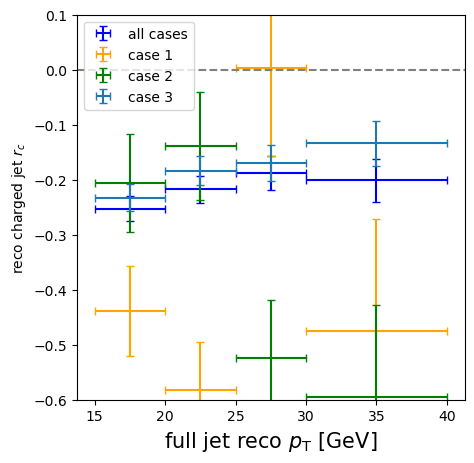

In [32]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], rc_allfake_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_allfake_bs_vs_pts_array, capsize=3, color='b', ls='none', label='all cases')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_fake1_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_fake1_bs_vs_pts_array, capsize=3, color='orange', ls='none', label='case 1')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_fake2_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_fake2_bs_vs_pts_array, capsize=3, color='g', ls='none', label='case 2')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_fake3_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_fake3_bs_vs_pts_array, capsize=3, ls='none', label='case 3')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')
plt.title('')

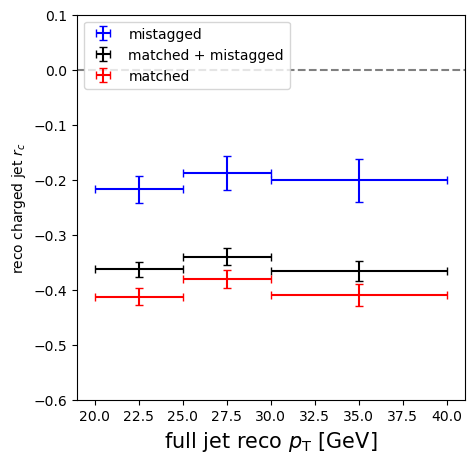

In [33]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_allfake_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_allfake_bs_vs_pts_array[1:], capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([22.5, 27.5, 35], rc_allreco_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_allreco_bs_vs_pts_array[1:], capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:], capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')
#plt.title('Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

In [34]:
np.array(rc_allreco_bs_vs_pts_array)-np.array(rc_match_bs_vs_pts_array)

array([0.05049298, 0.04976062, 0.04134469, 0.04356509])

1.2 Fake subtraction

In [48]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [49]:
df_match_20 = applyCut(df_match, '20 < pts < 25')
df_allreco_20 = applyCut(df_allreco, '20 < pts < 25')
df_fake_20 = applyCut(df_allfake, '20 < pts < 25')
df_fakejet_20 = applyCut(df_fakejet, '20 < pts < 25')
df_fakecorr_20 = applyCut(df_fakecorr, '20 < pts < 25')
df_notfakejet_20 = applyCut(df_notfakejet, '20 < pts < 25')

In [50]:
y_match_rec,yerr_match_rec,x = calc_hist(df_match_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_20['w'], density=True)
y_allreco_rec,yerr_allreco_rec,x = calc_hist(df_allreco_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_allreco_20['w'], density=True)
y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_20['w'], density=True)
y_fakejet_rec,yerr_fakejet_rec,x = calc_hist(df_fakejet_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fakejet_20['w'], density=True)
y_notfakejet_rec,yerr_notfakejet_rec,x = calc_hist(df_notfakejet_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_notfakejet_20['w'], density=True)
y_fakecorr_rec,yerr_fakecorr_rec,x = calc_hist(df_fakecorr_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fakecorr_20['w'], density=True)

In [45]:
print(y_fake_rec/sum(y_fake_rec))
print(yerr_fake_rec/sum(y_fake_rec))

[0.60864417 0.39135583]
[0.02912147 0.02331168]


In [51]:
print(y_match_rec/sum(y_match_rec))
print(yerr_match_rec/sum(y_match_rec))

[0.70636007 0.29363993]
[0.0189809  0.01136867]


In [50]:
df_match_25 = applyCut(df_match, '25 < pts < 30')
df_allreco_25 = applyCut(df_allreco, '25 < pts < 30')
df_fake_25 = applyCut(df_allfake, '25 < pts < 30')
df_fakejet_25 = applyCut(df_fakejet, '25 < pts < 30')
df_fakecorr_25 = applyCut(df_fakecorr, '25 < pts < 30')
df_notfakejet_25 = applyCut(df_notfakejet, '25 < pts < 30')

In [51]:
y_match_rec,yerr_match_rec,x = calc_hist(df_match_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_25['w'])
y_allreco_rec,yerr_allreco_rec,x = calc_hist(df_allreco_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_allreco_25['w'])
y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_25['w'])
y_fakejet_rec,yerr_fakejet_rec,x = calc_hist(df_fakejet_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fakejet_25['w'])
y_fakecorr_rec,yerr_fakecorr_rec,x = calc_hist(df_fakecorr_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fakecorr_25['w'])
y_notfakejet_rec,yerr_notfakejet_rec,x = calc_hist(df_notfakejet_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_notfakejet_25['w'])

In [54]:
print(y_fake_rec/sum(y_fake_rec))
print(yerr_fake_rec/sum(y_fake_rec))

[0.59417459 0.40582541]
[0.02493272 0.02715528]


In [56]:
df_match_30 = applyCut(df_match, '30 < pts < 40')
df_allreco_30 = applyCut(df_allreco, '30 < pts < 40')
df_fake_30 = applyCut(df_allfake, '30 < pts < 40')
df_fakejet_30 = applyCut(df_fakejet, '30 < pts < 40')
df_fakecorr_30 = applyCut(df_fakecorr, '30 < pts < 40')
df_notfakejet_30 = applyCut(df_notfakejet, '30 < pts < 40')

In [57]:
y_match_rec,yerr_match_rec,x = calc_hist(df_match_30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_30['w'])
y_allreco_rec,yerr_allreco_rec,x = calc_hist(df_allreco_30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_allreco_30['w'])
y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_30['w'])
y_fakejet_rec,yerr_fakejet_rec,x = calc_hist(df_fakejet_30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fakejet_30['w'])
y_fakecorr_rec,yerr_fakecorr_rec,x = calc_hist(df_fakecorr_30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fakecorr_30['w'])

In [60]:
print(y_fake_rec/sum(y_fake_rec))
print(yerr_fake_rec/sum(y_fake_rec))

[0.60064745 0.39935255]
[0.05058158 0.04618194]


2. pT correction

In [35]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)] ]

In [36]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[1])

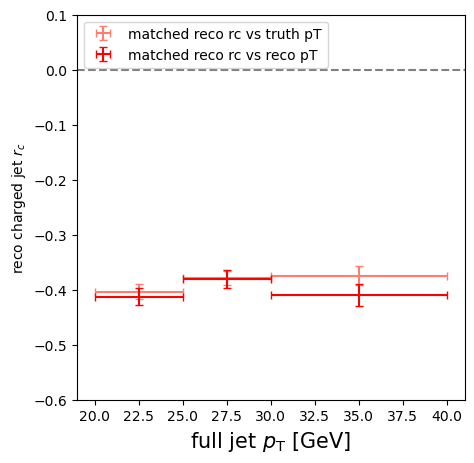

In [33]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:], capsize=3, color='salmon', ls='none', label='matched reco rc vs truth pT')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:], capsize=3, color='r', ls='none', label='matched reco rc vs reco pT')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')
#plt.title('Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

3. rc correction

In [24]:
rc_match_b_vs_pt_array = []
rc_err_match_b_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_b_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'b')[0])
    rc_err_match_b_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'b')[1])

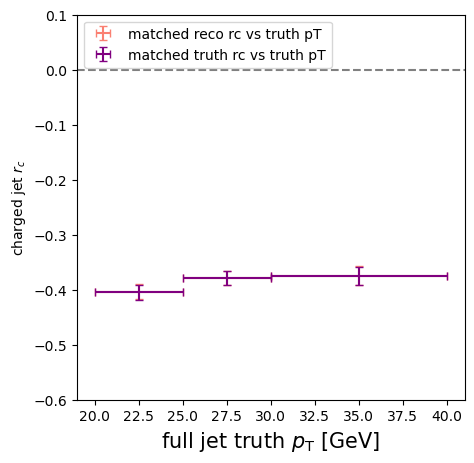

In [27]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:], capsize=3, color='salmon', ls='none', label='matched reco rc vs truth pT')
plt.errorbar([22.5, 27.5, 35], rc_match_b_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_b_vs_pt_array[1:], capsize=3, color='purple', ls='none', label='matched truth rc vs truth pT')
plt.xlabel('full jet truth $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')
#plt.title('Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

4. Efficiency correction

In [37]:
df_alltruth = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0615_chargedrc.root', "MatchedTree"),'pt!=-9 and b!=-9 and reject<=0 and rejects<=0')

In [38]:
df_alltruth_pt_array = [ df_alltruth[(df_alltruth.pt>15) & (df_alltruth.pt<20)],\
                       df_alltruth[(df_alltruth.pt>20) & (df_alltruth.pt<25)],\
                       df_alltruth[(df_alltruth.pt>25) & (df_alltruth.pt<30)],\
                       df_alltruth[(df_alltruth.pt>30) & (df_alltruth.pt<40)] ]

In [39]:
rc_alltruth_b_vs_pt_array = []
rc_err_alltruth_b_vs_pt_array = []
for i in range(0, len(df_alltruth_pt_array)):
    rc_alltruth_b_vs_pt_array.append(getRcAndErr(df_alltruth_pt_array[i], 'b')[0])
    rc_err_alltruth_b_vs_pt_array.append(getRcAndErr(df_alltruth_pt_array[i], 'b')[1])

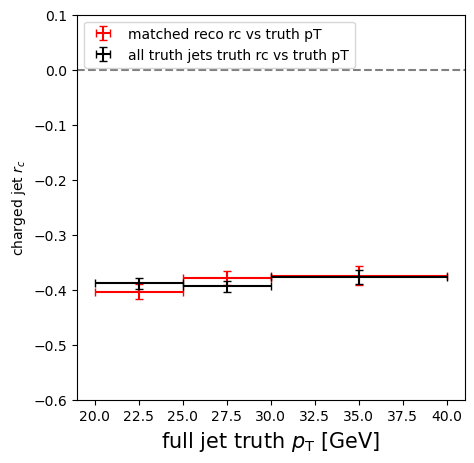

In [45]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:], capsize=3, color='r', ls='none', label='matched reco rc vs truth pT')
plt.errorbar([22.5, 27.5, 35], rc_alltruth_b_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_alltruth_b_vs_pt_array[1:], capsize=3, color='k', ls='none', label='all truth jets truth rc vs truth pT')
plt.xlabel('full jet truth $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')
#plt.title('Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

2-4. overall correction

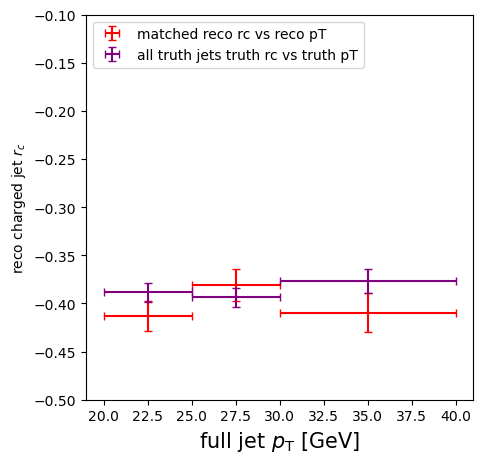

In [44]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:], capsize=3, color='r', ls='none', label='matched reco rc vs reco pT')
plt.errorbar([22.5, 27.5, 35], rc_alltruth_b_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_alltruth_b_vs_pt_array[1:], capsize=3, color='purple', ls='none', label='all truth jets truth rc vs truth pT')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.5,-0.1)
plt.legend(loc='upper left')
#plt.title('Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

In [43]:
print(np.asarray(rc_alltruth_b_vs_pt_array)-np.asarray(rc_match_bs_vs_pts_array))

[ 0.0418393   0.02445988 -0.01270079  0.03286606]
